<a href="https://colab.research.google.com/github/Arka13/GoogleColabRepo/blob/main/20261030_upgrad_boosting_concrete_strength_final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Boosting - Adaboost and Gradient Boosting

**The problem.** Concrete is tested by casting a sample, waiting (usually **28 days**), and crushing
it in a press to measure its **compressive strength**. That is slow and expensive. A construction
company wants to **predict strength from the mix recipe and its age**, so engineers can screen
recipes instantly and test only the promising ones. The answer is a number (strength in MPa), so this
is a **regression** problem.

**The data.** The UCI *Concrete Compressive Strength* dataset: about 1,000 lab tests. Each row is
one concrete mix (how many kg of each ingredient per m³), its age in days, and the measured strength.


**The storyline of this notebook**

| Step | Question we answer |
|---|---|
| 1 | What does the data look like? |
| 2 | Start with a Decision Tree. What is wrong with it? |
| 3 | **The fix:** keep the model simple, but train **many** of them one after another (**boosting**): AdaBoost and Gradient Boosting |
| 4 | Compare everything |

**How we'll score models**

| Metric | In plain words | Good value |
|---|---|---|
| **RMSE** | "By how many MPa is the prediction typically off?" | lower |
| **R²** | "How much of the variation in strength does the model explain?" (1 = all, 0 = none) | closer to 1 |

## Setup

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import AdaBoostRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, r2_score

RANDOM_STATE = 42

## 1: The Data

The code reads `concrete.csv` from your Colab folder if you uploaded it; otherwise it downloads it.

In [ ]:
df = pd.read_csv("/content/concrete.csv")

print(df.shape)
df.head()

(1030, 9)


,cement,slag,ash,water,superplastic,coarseagg,fineagg,age,strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


cement_level           Less cement  More cement
age_group                                      
Early (≤7 days)               13.2         29.2
Standard (14–28 days)         28.4         44.7
Mature (28+ days)             42.5         54.0


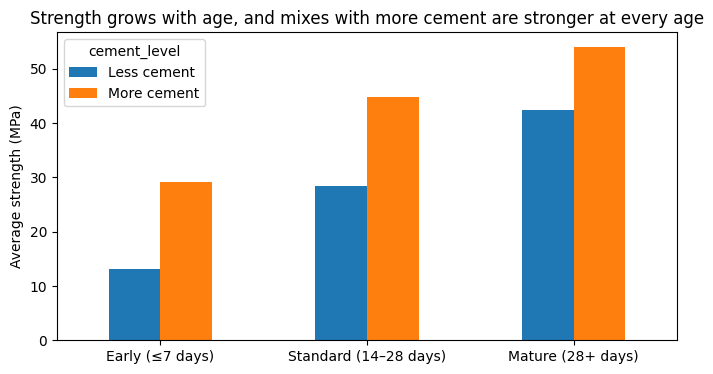

In [ ]:
df["age_group"] = pd.cut(df["age"], bins=[0, 7, 28, 365],
                         labels=["Early (≤7 days)", "Standard (14–28 days)", "Mature (28+ days)"])
df["cement_level"] = np.where(df["cement"] >= df["cement"].median(), "More cement", "Less cement")

avg = df.groupby(["age_group", "cement_level"])["strength"].mean().unstack()
print(avg.round(1))

avg.plot(kind="bar", figsize=(8, 4), rot=0)
plt.ylabel("Average strength (MPa)")
plt.xlabel("")
plt.title("Strength grows with age, and mixes with more cement are stronger at every age")
plt.show()

df = df.drop(columns=["age_group", "cement_level"])   # these were only for the plot

### Prepare the data

* **Remove duplicate rows.** The file contains a few identical lab records.
* All columns are numbers already, so no encoding is needed. Trees don't need scaling.

In [ ]:
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()

y = df["strength"]
X = df.drop(columns=["strength"])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE      # 80% train, 20% test
)
print("Training rows:", len(X_train), "| Test rows:", len(X_test), "| Features:", X.shape[1])

Duplicate rows: 25
Training rows: 804 | Test rows: 201 | Features: 8


A helper that scores any model on train and test, and stores the result for the final comparison:

In [ ]:
results = {}

def evaluate(name, model):
    pred_train, pred_test = model.predict(X_train), model.predict(X_test)
    scores = {
        "Train RMSE": np.sqrt(mean_squared_error(y_train, pred_train)),
        "Test RMSE":  np.sqrt(mean_squared_error(y_test, pred_test)),
        "Train R²":   r2_score(y_train, pred_train),
        "Test R²":    r2_score(y_test, pred_test),
    }
    results[name] = scores
    print(name)
    print(f"  RMSE  train: {scores['Train RMSE']:6.2f}   test: {scores['Test RMSE']:6.2f}")
    print(f"  R²    train: {scores['Train R²']:6.3f}   test: {scores['Test R²']:6.3f}")

## 2: Decision Tree

### Two ways a model can be wrong

| | **High bias** (underfitting) | **High variance** (overfitting) |
|---|---|---|
| In plain words | The model is **too simple** to capture the pattern | The model is **too complex**: it memorises the training rows |

### Our simple model: a decision tree with only 3 levels

A decision tree predicts by asking yes/no questions (*"Is age ≤ 21 days?"*, *"Is cement ≤ 355 kg?"*).
Each path ends in a **leaf**, and the prediction is the **average strength of the training rows in
that leaf**.

For classification, a tree measured how **mixed** a group was (Gini). For regression there are no
classes, so it measures how **spread out** the target is inside a group, using the
**mean squared error (MSE)** around the group's mean:

$$\text{MSE(group)} = \frac{1}{n}\sum_{i \in \text{group}} (y_i - \bar{y})^2$$

Every leaf predicts the **mean** of its training rows. A split is **good** when the two child
groups are *tighter* around their own means than the parent was. The tree tries every feature and
every threshold and keeps the one with the lowest **weighted** child MSE:

$$\text{score} = \frac{n_L}{n}\,\text{MSE}_L + \frac{n_R}{n}\,\text{MSE}_R$$

With `max_depth=3` the tree has at most **8 leaves**, so it can only ever give **8 different
answers** for every possible mix.

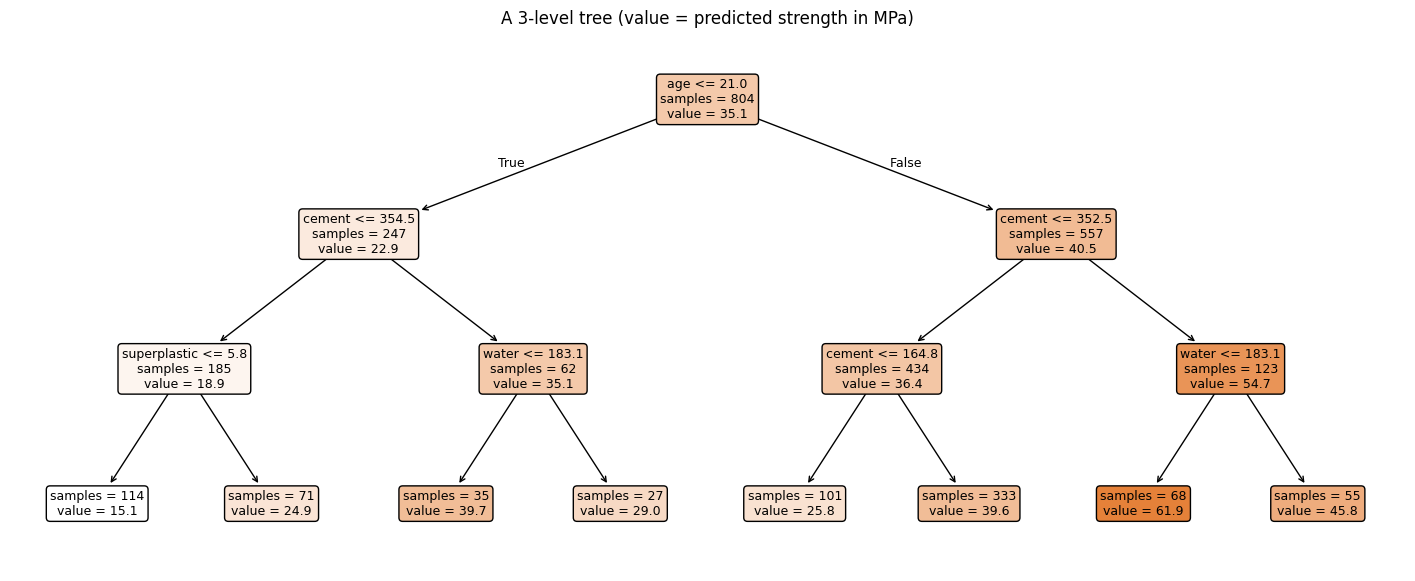

In [ ]:
simple_tree = DecisionTreeRegressor(max_depth=3, random_state=RANDOM_STATE)
simple_tree.fit(X_train, y_train)

plt.figure(figsize=(18, 7))
plot_tree(simple_tree, feature_names=X.columns, filled=True, rounded=True,
          impurity=False, precision=1, fontsize=9)
plt.title("A 3-level tree (value = predicted strength in MPa)")
plt.show()

In [ ]:
evaluate("Simple tree (depth 3)", simple_tree)

Simple tree (depth 3)
  RMSE  train:  10.02   test:  11.27
  R²    train:  0.608   test:  0.574


### Diagnosis

* Train R² and test R² are **close**: the model is **not** memorising.
* Both are **low**: it explains only about 60% of the variation, and it is typically off by about 11 MPa.

That is the signature of **high bias**. Let's see it by plotting predicted against actual strength.
A perfect model would put every point on the diagonal line.

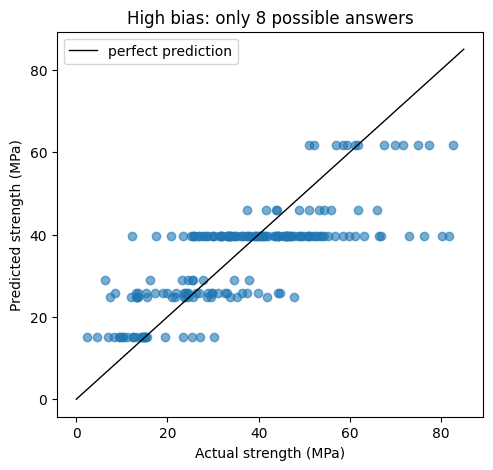

In [ ]:
pred = simple_tree.predict(X_test)

plt.figure(figsize=(5.5, 5))
plt.scatter(y_test, pred, alpha=0.6)
plt.plot([0, 85], [0, 85], color="black", lw=1, label="perfect prediction")
plt.xlabel("Actual strength (MPa)")
plt.ylabel("Predicted strength (MPa)")
plt.title("High bias: only 8 possible answers")
plt.legend(loc="upper left")
plt.show()

## 3: The Fix — Boosting: Many Simple Trees, One After Another

**Boosting** keeps every tree **simple** (our depth-3 tree), but trains **many** of them in a
sequence. Each new tree concentrates on what the previous trees got **wrong**, and the final
prediction combines all of them.

Think of a team of students taking turns on a test: each one focuses on the questions the
previous ones got wrong. No single student needs to be brilliant.

There are two popular ways to tell the next tree "what was wrong":

| | **AdaBoost** | **Gradient Boosting** |
|---|---|---|
| How the next tree learns from mistakes | Badly predicted rows get **more weight** (more attention) | The next tree predicts the **leftover error** directly |



### 3a: AdaBoost — give the hard rows more attention

1. Every training row starts with the **same weight**.
2. Train a simple tree.
3. Rows it predicted **badly** get **more weight**; rows predicted well get less.
4. Train the next simple tree using these weights, so it pays more attention to the hard rows.
5. Repeat. In the end, all trees vote, and more accurate trees get a bigger say.

In [ ]:
ada = AdaBoostRegressor(
    estimator=DecisionTreeRegressor(max_depth=3),   # our simple tree
    n_estimators=500,                               # up to 500 trees in the sequence
    learning_rate=0.1,                              # how strongly each tree counts
    random_state=RANDOM_STATE,
)
ada.fit(X_train, y_train)
evaluate("AdaBoost (depth-3 trees)", ada)

AdaBoost (depth-3 trees)
  RMSE  train:   6.87   test:   7.90
  R²    train:  0.816   test:  0.791


A clear improvement over one simple tree (test R² up from about 0.57 to about 0.79), and train and
test still agree, so **no memorising**. But AdaBoost gets there slowly: changing the weights only
*hints* at what is wrong; it doesn't tell the next tree *how much* to correct.

### 3b: Gradient Boosting — predict the leftover error

Instead of hinting through weights, gradient boosting tells the next tree **exactly** what is still
wrong:

1. Start by predicting the average for every row.
2. Compute the **leftover error** for each row: `residual = actual − prediction`.
3. Train a simple tree to predict those residuals.
4. Add a **small fraction** of that tree's output to the prediction (the **learning rate**, e.g. 0.1).
5. Repeat.

In [ ]:
gbr = GradientBoostingRegressor(
    max_depth=3,              # the same simple tree
    n_estimators=1000,        # number of trees in the sequence
    learning_rate=0.1,        # how big each correction is
    random_state=RANDOM_STATE,
)
gbr.fit(X_train, y_train)
evaluate("Gradient Boosting (depth-3 trees)", gbr)

Gradient Boosting (depth-3 trees)
  RMSE  train:   1.63   test:   4.12
  R²    train:  0.990   test:  0.943


Watch the same predicted-vs-actual plot as trees are added:

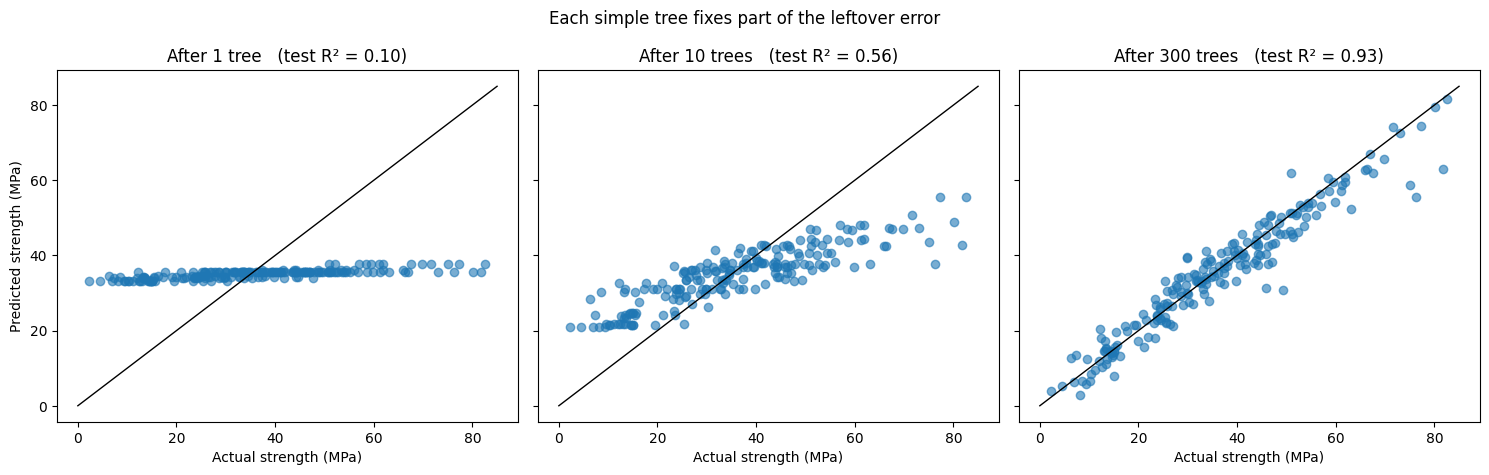

In [ ]:
# staged_predict gives the model's prediction after 1, 2, 3, ... trees
staged = list(gbr.staged_predict(X_test))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), sharex=True, sharey=True)
for ax, n in zip(axes, [1, 10, 300]):
    ax.scatter(y_test, staged[n - 1], alpha=0.6)
    ax.plot([0, 85], [0, 85], color="black", lw=1)
    label = "tree" if n == 1 else "trees"
    ax.set_title(f"After {n} {label}   (test R² = {r2_score(y_test, staged[n - 1]):.2f})")
    ax.set_xlabel("Actual strength (MPa)")
axes[0].set_ylabel("Predicted strength (MPa)")
plt.suptitle("Each simple tree fixes part of the leftover error")
plt.tight_layout()
plt.show()

* **1 tree:** every prediction is close to the average (we only add 10% of one tree's correction).
* **10 trees:** roughly as good as our single simple tree.
* **300 trees:** Every tree is still only 3 levels deep;
  the accuracy comes from **adding many small corrections**.

### 3c: How many trees?



In [ ]:
# scikit-learn holds back its own validation set (validation_fraction) from the training data
# and stops when the validation score hasn't improved for 50 rounds (n_iter_no_change).
gbr_es = GradientBoostingRegressor(
    max_depth=3,                 # still the same simple tree
    n_estimators=3000,           # upper limit; early stopping picks the real number
    learning_rate=0.1,
    subsample=0.8,               # each tree sees a random 80% of rows
    validation_fraction=0.2,     # 20% of training rows held back for early stopping
    n_iter_no_change=50,         # stop after 50 rounds with no improvement
    random_state=RANDOM_STATE,
)
gbr_es.fit(X_train, y_train)

print("Trees chosen by early stopping:", gbr_es.n_estimators_)
evaluate("Gradient Boosting (early stopping)", gbr_es)

Trees chosen by early stopping: 359
Gradient Boosting (early stopping)
  RMSE  train:   2.73   test:   4.86
  R²    train:  0.971   test:  0.921


## 4: Compare Everything

In [ ]:
summary = pd.DataFrame(results).T.round(3)
summary

,Train RMSE,Test RMSE,Train R²,Test R²
Simple tree (depth 3),10.024,11.273,0.608,0.574
AdaBoost (depth-3 trees),6.869,7.902,0.816,0.791
Gradient Boosting (depth-3 trees),1.633,4.120,0.990,0.943
Gradient Boosting (early stopping),2.731,4.861,0.971,0.921


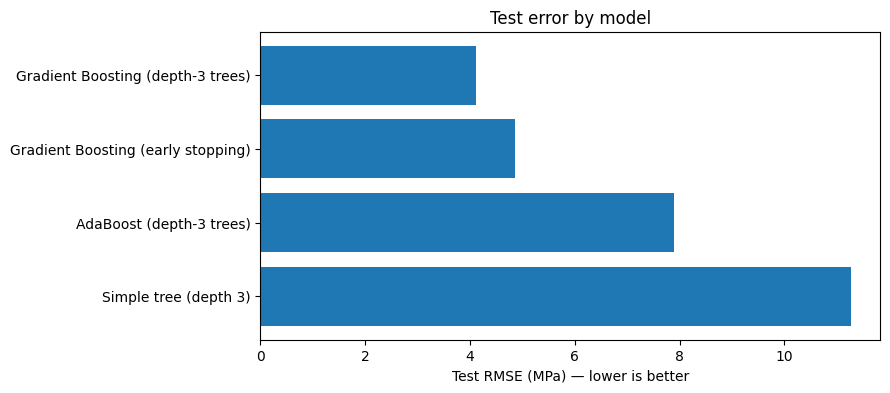

In [ ]:
order = summary.sort_values("Test RMSE")

plt.figure(figsize=(8, 4))
plt.barh(order.index, order["Test RMSE"])
plt.gca().invert_yaxis()
plt.xlabel("Test RMSE (MPa) — lower is better")
plt.title("Test error by model")
plt.show()

## Key Takeaways

1. We started with a **simple, high-bias** tree: easy to read, but too simple.
2. **Boosting** kept every tree simple and trained many in sequence, each fixing what was
   left. Test R² went from about 0.57 to about 0.94. A train/test gap does open up as trees are
   added, so the number of trees and the learning rate still need care.
3. **AdaBoost** points the next tree at mistakes by **re-weighting rows**. **Gradient Boosting**
   gives the next tree the **leftover error itself**, which is more direct, and it did much better here.

| Model | Learns from mistakes by… | Main risk |
|---|---|---|
| Simple tree | — | too simple (high bias) |
| AdaBoost | giving badly predicted rows more weight | slow progress if its trees are too simple |
| Gradient Boosting | predicting the leftover error | too many trees can overfit; use early stopping |
